# QM9 property steering: reproducing the figure

Rebuilds both panels of `figures/qm9_property_steering.pdf` from stored results, and shows
how to regenerate those results from the shipped checkpoints.

**What the figure claims.** The method's premise is that a flow map makes the value
function reachable by Monte Carlo where a denoiser can only approximate it. The left panel
measures that directly; the right panel shows it converting into better samples per network
call. Both panels are QM9, polarizability $\alpha$, and both put NFE on the $x$ axis.

**Cost.** Nothing here needs a GPU: every cell reads stored CSVs and redraws. The commands
that *produce* those CSVs are given in each section and do need one; their run times are
noted so you can pick.

In [1]:
from pathlib import Path
import csv, subprocess, sys
from collections import defaultdict

import numpy as np
import pandas as pd

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO / "scripts" / "paper"))
print("repo:", REPO)

repo: /n/netscratch/albergo_lab/Lab/uunneberg/MultiMFM


## 1. The value-function benchmark

For conditioning states drawn by integrating the base model to $t\sim\mathcal U(0.05,0.35)$,
how well does each estimator recover

$$V_t(x)=\log\mathbb E\!\left[e^{r(X_1)}\mid X_t=x\right]?$$

| estimator | what it is | cost | depends on $N$? |
|---|---|---|---|
| multiMFM | log-mean-exp over $N$ flow-map posterior samples | $N$ calls | **yes** |
| DPS | $r(\mathbb E[X_1\mid X_t])$, one-step denoiser point estimate | 1 call | no |
| FMAP | base ODE integrated $t\to1$, scored at that endpoint | steps to 1 | no |
| reference | the same log-mean-exp over 4,096 GLASS posterior samples | — | — |

Produced by (one GPU, ~25 min):

```bash
sbatch scripts/qm9/value_error.sbatch        # 32 states, 4,096-sample reference
```

In [2]:
ve = pd.read_csv(REPO / "results/qm9/value_error.csv")
piv = ve.pivot_table(index="n", columns="estimator", values="abs_value_error")
piv = piv[["multiMFM", "DPS", "FMAP", "reference self-split"]]
piv.round(3)

estimator,multiMFM,DPS,FMAP,reference self-split
n,,,,
1,27.334,21.266,29.678,0.062
2,15.018,21.266,29.678,0.062
4,7.590,21.266,29.678,0.062
8,4.257,21.266,29.678,0.062
16,2.178,21.266,29.678,0.062
32,1.582,21.266,29.678,0.062
64,1.082,21.266,29.678,0.062
128,0.510,21.266,29.678,0.062
256,0.399,21.266,29.678,0.062


Read off the three things the panel is for:

In [3]:
mfm = piv["multiMFM"]
floor = piv["reference self-split"].iloc[0]
print(f"multiMFM: {mfm.iloc[0]:.2f} at N=1  ->  {mfm.iloc[-1]:.3f} at N={mfm.index[-1]}")
print(f"  vs DPS  {piv['DPS'].iloc[0]:.2f} (flat): final ratio {piv['DPS'].iloc[0] / mfm.iloc[-1]:.0f}x")
print(f"  vs FMAP {piv['FMAP'].iloc[0]:.2f} (flat)")
crossed = mfm[mfm < piv["DPS"].iloc[0]]
print(f"  passes DPS at N = {crossed.index[0]}")
print(f"\nreference self-split floor: {floor:.3f}"
      f"  ({'below' if floor < mfm.iloc[-1] else 'ABOVE'} the last point -> "
      f"{'resolved' if floor < mfm.iloc[-1] else 'FLOOR-LIMITED'})")

multiMFM: 27.33 at N=1  ->  0.194 at N=512
  vs DPS  21.27 (flat): final ratio 110x
  vs FMAP 29.68 (flat)
  passes DPS at N = 2

reference self-split floor: 0.062  (below the last point -> resolved)


The floor matters and is easy to get wrong. The reference is itself a Monte-Carlo estimate,
and QM9's reward spans many orders of magnitude under $\exp$, so a small pool measures
nothing. Measured while building this:

| reference samples | self-split floor | DPS error | usable? |
|---|---|---|---|
| 32 | 7.69 | 5.79 | no — floor above the signal |
| 64 | 2.04 | 5.07 | marginal |
| 4,096 | **0.062** | 21.27 | yes |

(DPS's value differs between rows because the reference it is scored against differs.)

## 2. The steering benchmark

Held-out oracle MAE against forward-equivalent network calls. The like-for-like comparison
for multiMFM is **DPS**: both steer one trajectory and neither selects among candidates.
multiMFM-SS adds selection and is read against **best-of-$N$**.

Produced by (one GPU each; the grid is the long one, ~6 h):

```bash
sbatch scripts/qm9/lowbudget_final.sbatch     # ours + baselines, n=512 x 3 seeds
sbatch scripts/qm9/matched_grid.sbatch        # our points placed on the baselines' budget grid
sbatch scripts/qm9/lowbudget_twotime.sbatch   # two-time vs diagonal flow-map query
sbatch scripts/qm9/fk_ladder.sbatch           # Feynman-Kac after the resampling fix
python  scripts/paper/collect_final_steering.py
python  scripts/paper/collect_twotime.py
python  scripts/paper/collect_fk_ladder.py
```

In [4]:
import importlib
import qm9_steering_figure as qsf          # the figure's own data loader, so this cannot drift
importlib.reload(qsf)
d = qsf.load()

rows = []
for rung in qsf.LADDER:
    at = lambda m: dict((x, y) for x, y, _ in d.get(m, [])).get(rung)
    rows.append({"NFE": rung, "multiMFM": at("ours"), "multiMFM-SS": at("ours_ss"),
                 "DPS": at("dps"), "best-of-N": at("best_of_n"), "Feynman-Kac": at("fk")})
steer = pd.DataFrame(rows).set_index("NFE")
steer.round(3)

,multiMFM,multiMFM-SS,DPS,best-of-N,Feynman-Kac
NFE,,,,,
256,2.851,1.875,3.051,5.824,5.964
512,1.479,1.311,2.477,3.592,3.629
1024,1.479,1.240,2.477,2.266,2.308
2048,1.120,1.199,2.477,1.466,1.467


In [5]:
ratio = (steer["DPS"] / steer["multiMFM"]).round(2)
print("multiMFM vs DPS (like-for-like, neither selects):")
for n, r in ratio.items():
    print(f"  {n:>5} NFE: {r:.2f}x")
print("\nmultiMFM-SS vs best-of-N at the same budget:")
for n in steer.index:
    print(f"  {n:>5} NFE: {steer.loc[n, 'multiMFM-SS']:.3f} vs {steer.loc[n, 'best-of-N']:.3f}")

multiMFM vs DPS (like-for-like, neither selects):
    256 NFE: 1.07x
    512 NFE: 1.67x
   1024 NFE: 1.67x
   2048 NFE: 2.21x

multiMFM-SS vs best-of-N at the same budget:
    256 NFE: 1.875 vs 5.824
    512 NFE: 1.311 vs 3.592
   1024 NFE: 1.240 vs 2.266
   2048 NFE: 1.199 vs 1.466


Feynman--Kac sits on top of best-of-$N$. That is the corrected result, not an omission: its
resampling used to be unconditional, which loses particle diversity even under uniform
weights, and at $\lambda=0$ it scored 8.85 where best-of-$N$ scores 3.59 — it had collapsed
to best-of-1. With resampling gated on effective sample size, $\lambda=0$ reproduces
best-of-$N$ (3.63 vs 3.59) and is also where its pilot puts it, so on QM9 it *is* best-of-$N$.

## 3. Redraw the figure

In [6]:
out = subprocess.run([sys.executable, "scripts/paper/qm9_figure.py"],
                     cwd=REPO, capture_output=True, text=True)
print(out.stdout.strip() or out.stderr.strip()[-800:])

wrote figures/qm9_property_steering.pdf
wrote figures/qm9_property_steering.png


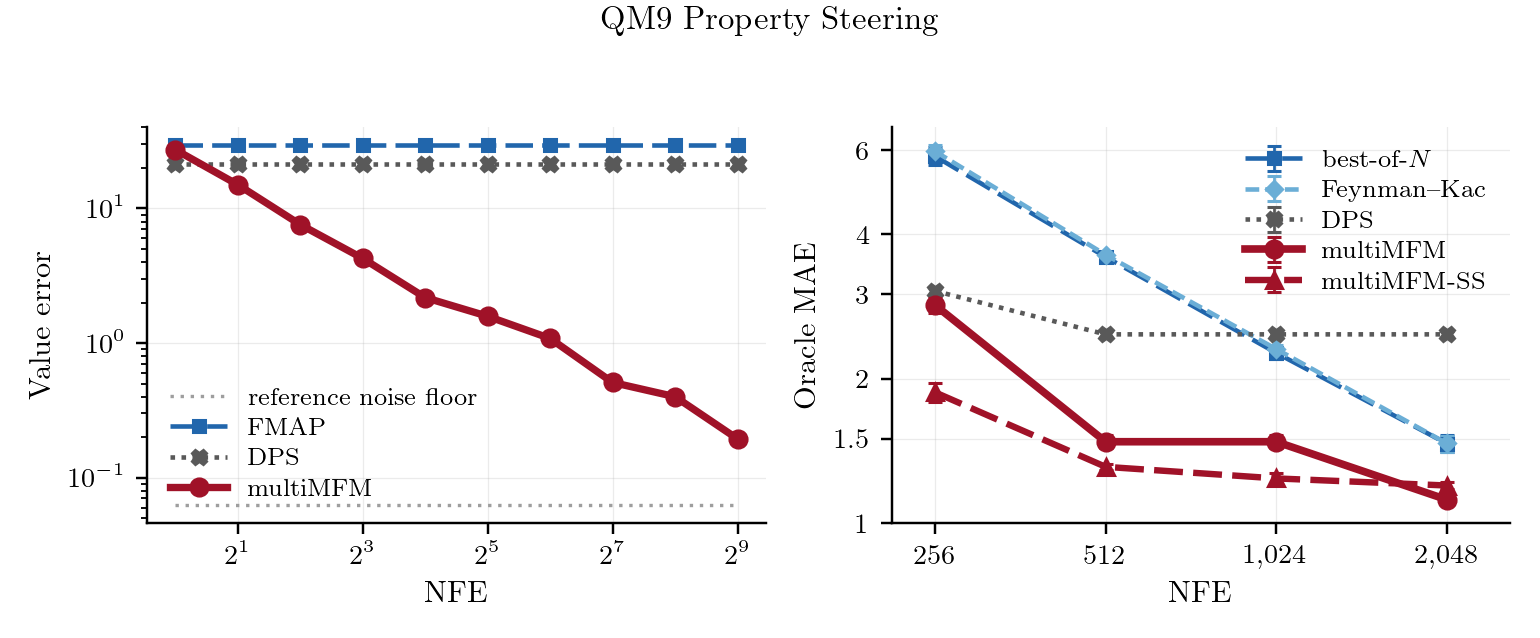

In [7]:
from IPython.display import Image, display
display(Image(filename=str(REPO / "figures/qm9_property_steering.png")))

## What to check if a number moves

* **The floor.** If `reference self-split` is not below every plotted point, the panel is
  measuring the reference's noise, not the estimators. Raise `--n-ref`.
* **The validity floor.** Every QM9 point must clear PoseBusters $\ge0.75$, applied to every
  method alike; dropping it flatters whichever method trades validity hardest.
* **The budget rule.** Each method is shown at the best error it reaches with *at most* that
  budget. Applied to one method and not another it would be selection, not a comparison.
* **Scope.** Both panels are $\alpha$ only. The other five properties of Table 2 are not
  swept at low budget.